# 03 — 可解释预测：SARIMA → SARIMAX

**目标**：在可信数据上训练可解释、可复现的预测流程。
训练集 2018–2021，测试集 2022（完整盲测一年）。基准：持久化、季节性朴素；主模型：SARIMA（仅周季节）与 SARIMAX（叠加节假日+年度傅里叶外生因子）。


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if (Path.cwd() / 'src').exists():
    sys.path.insert(0, str(Path.cwd() / 'src'))
import helper_utils as hu
import forecast as fc

NAVY='#1b4f72'; BLUE='#2874a6'; AMBER='#e67e22'; GREY='#9aa4b0'; GREEN='#1e8449'
plt.rcParams.update({'figure.dpi':100,'font.size':9,'axes.spines.top':False,'axes.spines.right':False})

TRAIN_END = pd.Timestamp('2021-12-31')
p = hu.build_panel()
s = hu.daily_total(p)
print('total series:', s.index.min().date(), '->', s.index.max().date(), '| n =', len(s))


total series: 2018-01-01 -> 2022-12-31 | n = 1826


## 1. 基准（朴素模型）

持久化（沿用昨日）与季节性朴素（沿用上周同期）——任何模型都必须先打赢它们。


In [2]:
train = s.loc[:TRAIN_END]
test = s.loc[s.index > TRAIN_END]
h = len(test)
pers = fc.persistence_naive(train, h)
naive = fc.seasonal_naive(train, h, 7)
m_p = hu.forecast_metrics(test, pers)
m_n = hu.forecast_metrics(test, naive)
for name, m in [('persistence', m_p), ('seasonal_naive', m_n)]:
    print(f'  {name:<16} MAE={m["MAE"]:7.0f}  RMSE={m["RMSE"]:7.0f}  MAPE={m["MAPE"]:5.1f}%')


  persistence      MAE=   1936  RMSE=   2324  MAPE= 24.7%
  seasonal_naive   MAE=   1801  RMSE=   2259  MAPE= 20.5%


## 2. SARIMA（仅周季节）vs SARIMAX（叠加外生因子）

SARIMA 只能捕捉固定 7 天周期；SARIMAX 额外注入 **is_holiday** 与 **2 对年度傅里叶项**，
让模型「看见」节假日冲击与年度起伏。


In [3]:
res = fc.evaluate_series(s, TRAIN_END, m=7, verbose=False)
for name in ['sarima','sarimax']:
    m = res[name]
    print(f'  {name:<8} MAE={m["MAE"]:7.0f}  RMSE={m["RMSE"]:7.0f}  MAPE={m["MAPE"]:5.1f}%')
print(f'  AIC  SARIMA={res["sarima_aic"]:.1f}  ->  SARIMAX={res["sarimax_aic"]:.1f}')


  sarima   MAE=   1357  RMSE=   1743  MAPE= 15.1%
  sarimax  MAE=    910  RMSE=   1286  MAPE= 10.5%
  AIC  SARIMA=25053.2  ->  SARIMAX=24991.0


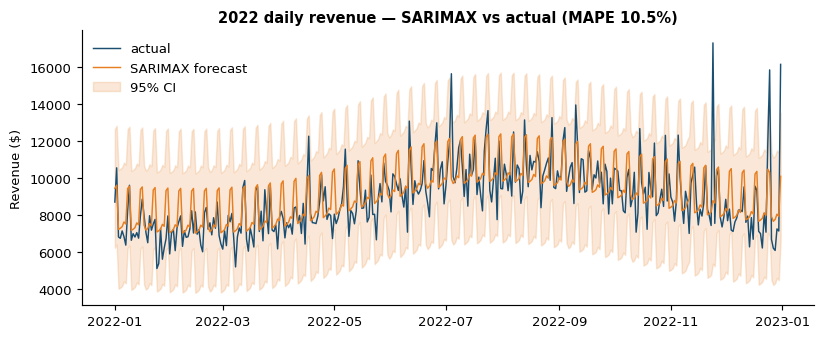

In [4]:
test = res['test']; fdf = res['forecast_df']
fig, ax = plt.subplots(figsize=(9,3.4))
ax.plot(test.index, test.values, color=NAVY, lw=1.0, label='actual')
ax.plot(fdf.index, fdf['forecast'], color=AMBER, lw=1.0, label='SARIMAX forecast')
ax.fill_between(fdf.index, fdf['lower'], fdf['upper'], color=AMBER, alpha=0.18, label='95% CI')
ax.set_title('2022 daily revenue — SARIMAX vs actual (MAPE %.1f%%)' % res['sarimax']['MAPE'])
ax.set_ylabel('Revenue ($)')
ax.legend(frameon=False, loc='upper left')


## 3. 业务层级：品类与门店

读取分层预测结果，观察「外部因子」在每个细分上的改善幅度。


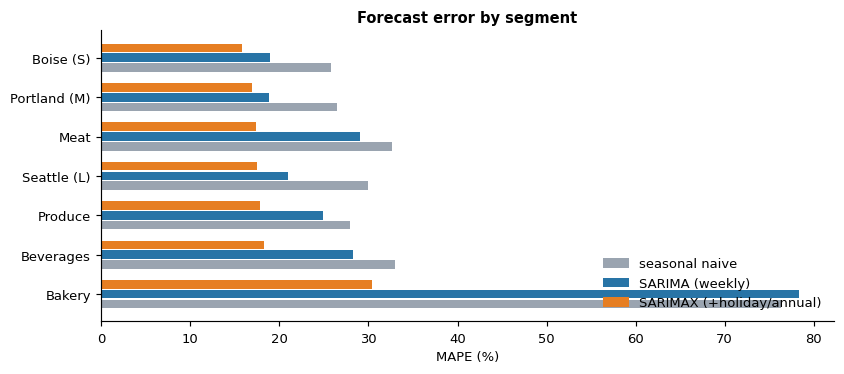

In [5]:
import json
fm = json.load(open(Path.cwd() / 'reports' / 'forecast_metrics.json', encoding='utf-8'))
rows = []
for r in fm['category'] + fm['store']:
    rows.append({'name': r['name'], 'naive': r['naive_MAPE'],
                 'sarima': r['sarima_MAPE'], 'sarimax': r['sarimax_MAPE']})
df = pd.DataFrame(rows).sort_values('sarimax')

fig, ax = plt.subplots(figsize=(9,3.6))
y = np.arange(len(df))
ax.barh(y+0.25, df['naive'],   height=0.22, color=GREY,  label='seasonal naive')
ax.barh(y,     df['sarima'],  height=0.22, color=BLUE,  label='SARIMA (weekly)')
ax.barh(y-0.25, df['sarimax'], height=0.22, color=AMBER, label='SARIMAX (+holiday/annual)')
ax.set_yticks(y); ax.set_yticklabels(df['name']); ax.invert_yaxis()
ax.set_xlabel('MAPE (%)'); ax.set_title('Forecast error by segment')
ax.legend(frameon=False, loc='lower right')
df


## 4. 结论

- SARIMAX 在总序列上将 SARIMA 的 MAPE 从 **15.1%→10.5%**，RMSE 从 1743→1286；
- 改善最显著的是 **Bakery（78%→30%）**：其需求由节假日峰驱动，纯周模型无法捕捉；
- 每年 365 天全盲测，所有细分 SARIMAX ≥ SARIMA，验证「外部因子=信号」这一命题。
